In [10]:
# Setup module: load packages
import QuantLib as ql
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

In [11]:
# Setup module: load data
# Find the repository root
def find_repo_root():
    path = Path.cwd().resolve()

    for parent in [path, *path.parents]:
        if (parent / "requirements.txt").exists():
            return parent

    raise FileNotFoundError(
        "Repository root could not be found. "
        "Make sure you are running this notebook from within the repository."
    )


# Data directory
repo_root = find_repo_root()
data_directory = repo_root / "data"

# Load €STR curve data
ESTR_file = data_directory / "ESTR 20260820.xlsx"

ESTR_data = pd.read_excel(
    ESTR_file,
    sheet_name="Data",
    skiprows=0
)

# Load €STR swap cash flows
ESTR_swap_cf_file = data_directory / "ESTR swap 20260803.xlsx"

ESTR_swap_cashflows = pd.read_excel(
    ESTR_swap_cf_file,
    sheet_name="Cash Flows"
)


# ESTR

In this module you'll learn about the concepts: overnight ESTR and ESTR swaps. You'll learn how to construct and manage ESTR indices using QuantLib. 

## 1. Introduction to the overnight ESTR and ESTR index

The euro short-term rate (ESTR) reflects the wholesale euro unsecured overnight borrowing costs of banks located in the euro area. The overnight ESTR rate is published by the ECB at 08:00 CET. The rate is based entirely on daily confidential statistical information relating to money market transactions in the market. 

The ESTR rate published by the ECB on a specific date is called the 'fixing'. You can find the current and historical ESTR fixings on the ECB website (https://data.ecb.europa.eu/data/datasets/EST/EST.B.EU000A2X2A25.WT). The past fixings form a timeseries called the ESTR index.

More background information on ESTR rates is contained here (https://www.ecb.europa.eu/stats/financial_markets_and_interest_rates/euro_short-term_rate/html/index.en.html). Go to the websites and find the term and latest fixing.


### ESTR as risk free rate
Because €STR is based on unsecured overnight money market transactions and contains minimal credit and liquidity risk, it is generally regarded as the euro area's closest approximation of a risk-free interest rate. As a result, €STR and the associated €STR swap curve have become the market standard for discounting collateralised derivative cash flows and for constructing risk-free yield curves used in valuation and risk management. That is the reason the ESTR fixing is very important for our valuation and risk computations.

## 2. ESTR index in QuantLib

QuantLib provides predefined index objects that can represent indices such as the ESTR index. 

Learn more on QuantLib index objects here (https://quantlib-python-docs.readthedocs.io/en/latest/indexes.html#index)

Now let's create an ESTR index object in QuantLib and explore some of its functionalities. To create an index in QuantLib, you first need to create a so-called 'handle', which is an object that can be linked to a term structure object later. We'll skip the details on this handle for now. It will be explained later in this episode :)

In [12]:
ESTR_curve_handle = ql.RelinkableYieldTermStructureHandle()
ESTR_index        = ql.Eonia(ESTR_curve_handle)

print(f"""
name():           {ESTR_index.name()}
fixingCalendar(): {ESTR_index.fixingCalendar()}
dayCounter():     {ESTR_index.dayCounter()}
currency():       {ESTR_index.currency()}
""")


name():           EoniaON Actual/360
fixingCalendar(): TARGET calendar
dayCounter():     Actual/360 day counter
currency():       European Euro



The advantage of the ESTR index in QuantLib is that it already sets some of the parameters to the correct values, such as the fixing calendar and the currency. These values are predefined in the ql.Eonia() index constructor function. There are several other indices available as well, such as ql.Sonia() or ql.Sofr(). We will remain within the EONIA index family, of which €STR is a member.

As explained before, the ESTR index is a series of historical ESTR fixings published by the ECB. When you create a QuantLib index object, the fixing history is not filled yet. You can check if a historical fixing is available by using the following function.

In [13]:
# Check if the ESTR index object contains a historical fixing for August 20th 2026
ESTR_index.hasHistoricalFixing(ql.Date(20,8,2026))

False

A QuantLib index object allows you to store historical fixings yourself. You can add a fixing to the index object using addFixing() with a fixing value and fixing date.

For example, the fixing for the ESTR rate on August 20, 2026 is 

In [14]:
# Add fixing for August 20th 2026
fixingDate = ql.Date(20,8,2026)
fixingValue = 0.02191

ESTR_index.addFixing(fixingDate, fixingValue)

# print the check if the fixing is available
print(f'Fixing available for {fixingDate}? {ESTR_index.hasHistoricalFixing(fixingDate)}')

# print fixing from index:
print(f'Fixing for {fixingDate} is {ESTR_index.fixing(fixingDate)}')

Fixing available for August 20th, 2026? True
Fixing for August 20th, 2026 is 0.02191


Sometimes it can be necessary to clear all fixings from all indices in your project. This can be done by the index manager, a global QuantLib object that has access to all index objects. Run the clearHistories() as given below and check if the fixing of your ESTR index is still available.

In [15]:
ql.IndexManager.instance().clearHistories() # remove fixing history
print(f'Fixing available for {fixingDate}? {ESTR_index.hasHistoricalFixing(fixingDate)}')

Fixing available for August 20th, 2026? False


## 3. Introduction to ESTR term structure
The overnight ESTR rate only provides the risk-free interest rate for a single day. However, many financial instruments generate cash flows far into the future. To value these cash flows, we need risk-free interest rates for all maturities, not just for overnight borrowing.

The market provides these longer-dated risk-free rates through ESTR swaps. The fixed rates quoted in the ESTR swap market can be used to derive a term structure of risk-free interest rates across different maturities. This term structure, often referred to as the ESTR discount curve, forms the foundation for the valuation and risk management of financial instruments.

### ESTR swaps
An €STR swap is a contract between two parties to exchange a fixed interest rate for a floating interest rate linked to €STR. One party pays a fixed rate throughout the life of the swap, while the other pays the realised compounded daily €STR rate.

For example, consider a 10-year €STR swap. One party agrees to pay a fixed rate over the next 10 years and receives the compounded overnight €STR rate in return. The other party takes the opposite position.

Because only the net interest payments are exchanged and no principal changes hands, swaps provide an efficient way to gain or hedge long-term interest rate exposure. As a result, the €STR swap market has become one of the largest and most liquid financial markets and is widely used by banks, pension funds, insurers and asset managers.

We will examine the mechanics of €STR swaps in more detail later. First, it is useful to understand how the swap rates relate to the €STR quotes in our dataset.

### ESTR swap rates

The €STR published by the ECB represents the overnight borrowing costs in the euro money market. While this rate applies to a single overnight period, market participants are also interested in risk-free interest rates over much longer horizons. For example, what fixed rate would investors be willing to exchange today for receiving overnight €STR cash flows over the next 10 years?

This is where €STR swap rates come in. The quoted swap rate is the fixed rate that can be exchanged for future €STR-based cash flows in a swap. More formally, it is the rate that makes the value of the fixed leg equal to the value of the floating €STR leg when the swap is initiated.

For example, in our dataset (ESTR 20260820.xlsx), the 10-year €STR swap rate is 3.03%.

This means that market participants are currently willing to lock in a fixed rate of 3.03% per annum for the next 10 years instead of receiving the realised overnight €STR rate over that period. Put differently, the market values a stream of future overnight €STR cash flows as economically equivalent to receiving a fixed rate of 3.03% per year for 10 years.

The 10-year ESTR swap rate in the data is 3.03%


,Term,Market Rate,Year Fraction
23,10 YR,3.03,10.0


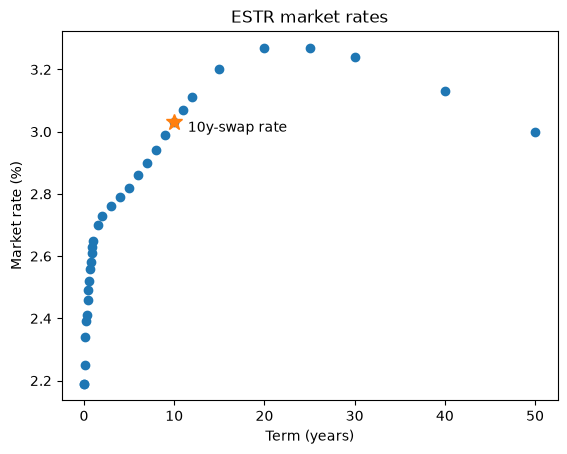

In [16]:
# Get the 10-year ESTR swap rate from our ESTR dataset
print(f"The 10-year ESTR swap rate in the data is {float(ESTR_data[ESTR_data['Year Fraction']==10]['Market Rate'].iloc[0])}%")

# plot the 10-year ESTR swap rate

plt.plot(ESTR_data['Year Fraction'], ESTR_data['Market Rate'], marker='o', linestyle='')

highlight_year = 10
subset = ESTR_data[ESTR_data['Year Fraction']==highlight_year]
plt.plot(subset['Year Fraction'], subset['Market Rate'], marker='*',markersize=12)
plt.annotate(f'10y-swap rate',xy=(11.5,3))

plt.title('ESTR market rates')
plt.xlabel('Term (years)')
plt.ylabel('Market rate (%)')

# get the data table
ESTR_data[ESTR_data['Year Fraction']==10]

Now try to find the 30-year ESTR swap rate in the dataset. Plot and explain in your own words what it represents.

In [17]:
# your implementation here

## ESTR swaps in more detail
To get a better understanding of ESTR swaps, let's have a look at the cash flow schedule of a 10-year fixed-for-floating ESTR swap, see data/ESTR swap 20260803.xslx. This file contains information on a 10-year ESTR receiver swap and the Cash Flow sheet contains the cashflows corresponding to this swap.

$\rightarrow$ When talking about a receiver swap, it means that you're looking at the swap from the perspective of a fixed-rate receiver.

Open de Excel file and have a look at the Settings. Some important settings are explained below:
- Notional is 10 million. The notional is used to compute the cashflows based on the coupon rates, both for floating and fixed coupons.
- The currency is Euros
- The effective date is August 3, 2026
- The tenor is 10 years
- The fixed rate coupon is 3.1315%. This is different from our previous 10-year swap rate, because this swap data originates from another date. 
- The payment frequency for the fixed leg is annual. So each year there's one payment corresponding to the fixed rate
- The payment frequency for the floating leg is semiannual. So each half year, there's one payment corresponding to the floating rate. 
- The index corresponding to the floating leg is ESTRON, which is the ESTR index as explained in this file. 

Let's have a closer look at the Cash Flows corresponding to this swap. 

,Pay Date,Payments(Rcv),Payments(Pay),Net Payments,Discount,PV
0,2027-02-04,0.00,-128428.25,-128428.25,0.987488,-126821.35
1,2027-08-04,308342.80,-137593.63,170749.17,0.973932,166298.01
2,2028-02-04,0.00,-144959.53,-144959.53,0.960162,-139184.66
3,2028-08-04,309199.31,-141069.91,168129.40,0.946806,159186.00
4,2029-02-06,0.00,-143082.50,-143082.50,0.933450,-133560.32
5,2029-08-06,307486.29,-141535.75,165950.54,0.920422,152744.60
6,2030-02-05,0.00,-146510.50,-146510.50,0.907131,-132904.17
7,2030-08-06,308342.80,-144206.22,164136.58,0.894235,146776.72
8,2031-02-04,0.00,-151061.89,-151061.89,0.880926,-133074.29
9,2031-08-05,308342.80,-148753.76,159589.04,0.868014,138525.46


Text(0, 0.5, 'Cash flow (millions)')

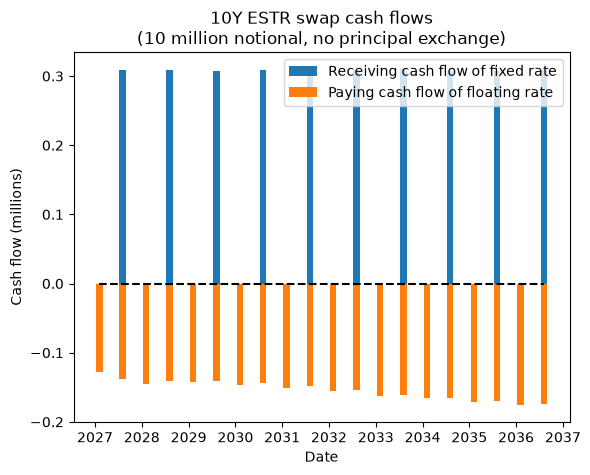

In [18]:
# Check the ESTR swap cash flow data
display(ESTR_swap_cashflows)

# Visualize the cash flows
plt.bar(ESTR_swap_cashflows['Pay Date'], ESTR_swap_cashflows['Payments(Rcv)']/1e6, width=50, label='Receiving cash flow of fixed rate')
plt.bar(ESTR_swap_cashflows['Pay Date'], ESTR_swap_cashflows['Payments(Pay)']/1e6, width=50, label='Paying cash flow of floating rate')
plt.hlines(0,xmin=min(ESTR_swap_cashflows['Pay Date']), xmax=max(ESTR_swap_cashflows['Pay Date']), color='black', linestyles='--')
plt.title(f'10Y ESTR swap cash flows\n(10 million notional, no principal exchange)')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Cash flow (millions)')

Some observations on the ESTR swap cash flows:
- The fixed leg payments (blue bars) represent cash flows received once a year, corresponding to the annual payment of the fixed leg. These cash flows are all the same throughout the life of the swap, because it's related to the swap fixed rate of 3.13%. 
- The floating leg payments (orange bars) represent cash flows paid twice a year, corresponding to the semiannual paymetn of the floating leg. As you can see, these cash flows are not all equal. That is due to the dependency on the floating rate. 

This last point is very important in order to understand swaps. The floating rate cash flow is based on the ESTR rate at that moment in time. When this swap is constructed, we don't exactly know what this ESTR rate will be in the future. Therefore, the cash flows given in the swap cash flow table are expectations of what the market believes these cash flows will be over the term of the swap contract.

## 4. Wrap up
By now you should understand the following concepts: 
- What is the ESTR fixing published by the ECB every day
- Why is the ESTR fixing relevant to investors? 
- What are ESTR swaps